# Practical Assignment: Performance Evaluation of Regression Models

**Application:** Predicting individual medical insurance charges from personal and lifestyle details.

**Name :- *Shravani Minache*
**Div:-A  Batch:-A3**
**PRN :- 202401040304**

**Aim:** Develop a regression model for a real-world application, evaluate it with suitable metrics, and implement and analyze Gradient Descent optimization for Linear Regression.

**Dataset:** Medical Cost Personal Dataset – 1338 records with 6 input features (age, sex, bmi, children, smoker, region) and a continuous target (`charges`). The CSV is loaded directly from GitHub, so an internet connection is required.

## 1. Import libraries

The notebook uses pandas and NumPy for data handling, Matplotlib and Seaborn for plots, and scikit-learn for splitting, scaling and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load and inspect the dataset

The target `charges` is a continuous number (USD), so this is a regression task.

In [2]:
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(url)

print("Dataset shape:", df.shape)
display(df.head())
display(df.describe().T)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

Dataset shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


,count,mean,std,min,25%,50%,75%,max
age,1338.0,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
bmi,1338.0,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
charges,1338.0,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


Missing values: 0
Duplicate rows: 1


In [3]:
# Remove duplicate rows (if any)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1337, 7)


## 3. Exploratory data analysis

A few plots to understand how the features relate to the insurance charges.

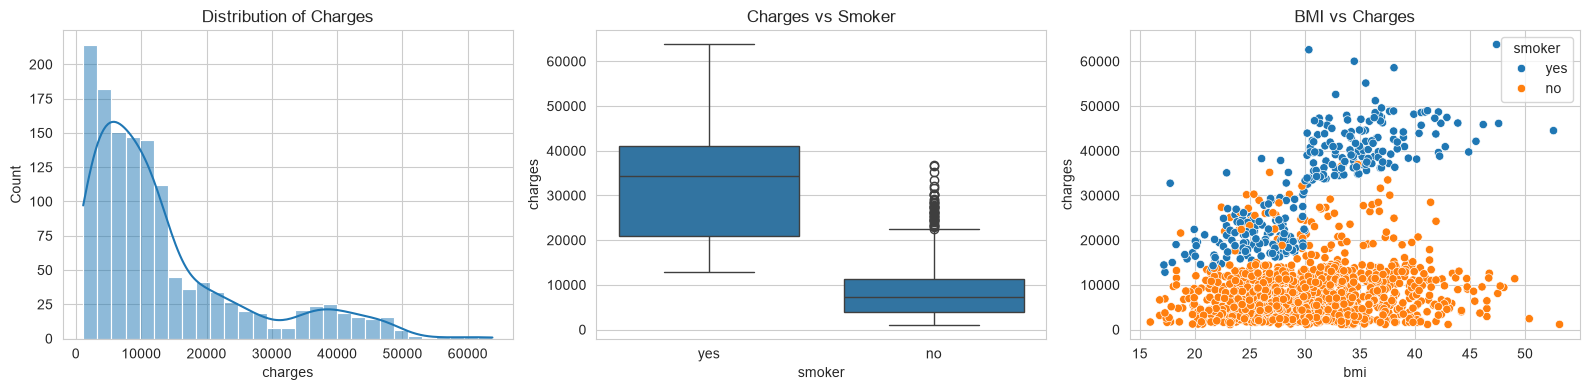

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df["charges"], kde=True, ax=ax[0]);                         ax[0].set_title("Distribution of Charges")
sns.boxplot(x="smoker", y="charges", data=df, ax=ax[1]);                 ax[1].set_title("Charges vs Smoker")
sns.scatterplot(x="bmi", y="charges", hue="smoker", data=df, ax=ax[2]);  ax[2].set_title("BMI vs Charges")
plt.tight_layout()
plt.show()

**Observation:** Charges are right-skewed. Smokers pay much more than non-smokers, and the cost rises with BMI, especially for smokers.

## 4. Prepare training and testing data

Categorical columns are converted to numeric using one-hot encoding. The split is performed **before** scaling, and the scaler is fitted only on the training features to avoid data leakage.

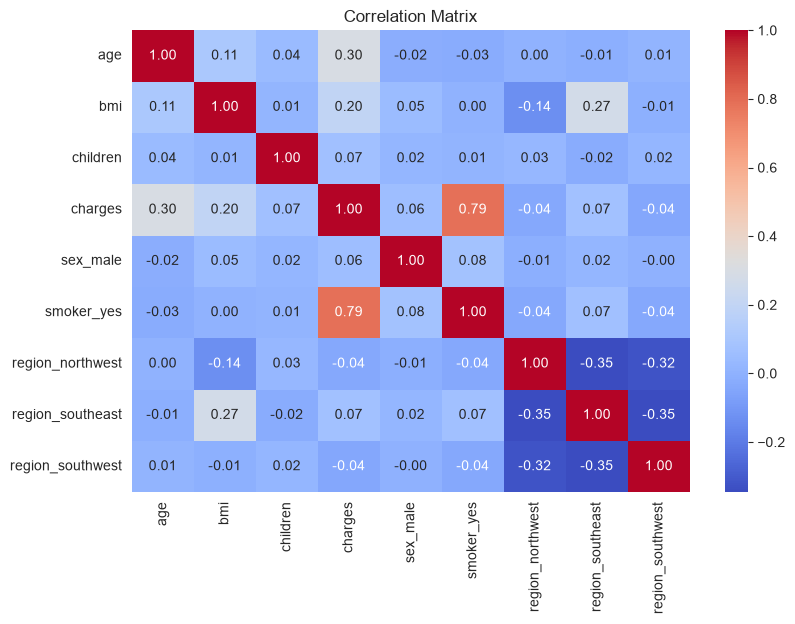

In [5]:
df_enc = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True).astype(float)

plt.figure(figsize=(9, 6))
sns.heatmap(df_enc.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [6]:
X = df_enc.drop(columns="charges")
y = df_enc["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Input features:", X_train.shape[1])

Training records: 1069
Testing records: 268
Input features: 8


## 5. Evaluation function

MAE and RMSE show the typical prediction error (in USD), MSE penalizes larger errors, and R² measures the share of variation in charges explained by the model.

In [7]:
def evaluate_regression(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2 Score": r2_score(y_true, y_pred)
    }

results = []

## 6. Linear Regression

Linear Regression estimates a linear relationship between the input features and the insurance charges. It is solved here with scikit-learn (closed-form solution) and acts as the reference for Gradient Descent.

In [8]:
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)
linear_predictions = linear_model.predict(X_test_scaled)

results.append(evaluate_regression(y_test, linear_predictions, "Linear Regression"))
display(pd.DataFrame(results).round(3))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4177.046,3.547802e+07,5956.343,0.807


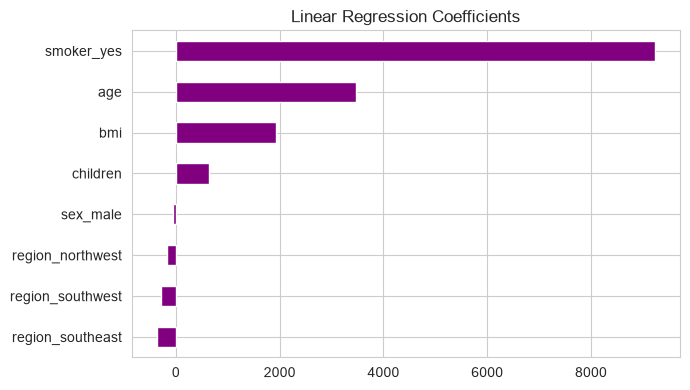

In [9]:
# Coefficients (features are standardized, so magnitudes are comparable)
coef = pd.Series(linear_model.coef_, index=X.columns).sort_values()
coef.plot(kind="barh", figsize=(7, 4), color="purple", title="Linear Regression Coefficients")
plt.tight_layout()
plt.show()

`smoker_yes` has by far the largest effect on charges, followed by `age` and `bmi`.

## 7. Linear Regression using Batch Gradient Descent

Gradient Descent updates the parameters in the direction that reduces the mean squared error:

$$w := w - \alpha \cdot \frac{2}{m} X^T (Xw - y)$$

Standardized features keep the updates on a comparable scale, and the target is centered by subtracting its training mean.

In [10]:
# Add a bias column of ones
X_train_gd = np.c_[np.ones(X_train_scaled.shape[0]), X_train_scaled]
X_test_gd  = np.c_[np.ones(X_test_scaled.shape[0]),  X_test_scaled]

y_mean = y_train.mean()
y_train_centered = y_train.to_numpy() - y_mean

def batch_gradient_descent(X, y, learning_rate=0.05, iterations=5000):
    weights = np.zeros(X.shape[1])
    loss_history = []
    for _ in range(iterations):
        errors = X @ weights - y
        gradient = (2 / len(y)) * (X.T @ errors)
        weights -= learning_rate * gradient
        loss_history.append(np.mean((X @ weights - y) ** 2))
    return weights, loss_history

gd_weights, loss_history = batch_gradient_descent(
    X_train_gd, y_train_centered, learning_rate=0.05, iterations=5000
)
gd_predictions = X_test_gd @ gd_weights + y_mean
results.append(evaluate_regression(y_test, gd_predictions, "Linear Regression (Batch GD)"))

print("Initial training MSE:", round(float(np.mean(y_train_centered ** 2)), 3))
print("Final training MSE  :", round(loss_history[-1], 3))
display(pd.DataFrame(results).round(3))

Initial training MSE: 136914670.12
Final training MSE  : 36979860.905


,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4177.046,3.547802e+07,5956.343,0.807
1,Linear Regression (Batch GD),4177.046,3.547802e+07,5956.343,0.807


## 8. Gradient Descent convergence

The loss curve shows how the training error decreases as the parameters are updated.

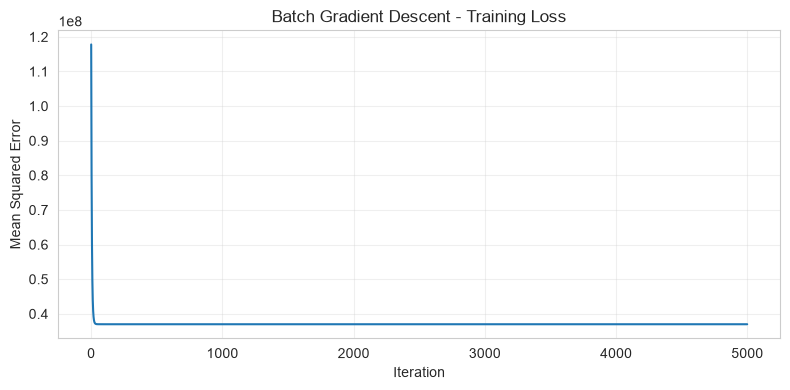

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title("Batch Gradient Descent - Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Effect of learning rate

A small learning rate takes longer to converge. A rate that is too large can make training unstable.

,Learning Rate,Final Training MSE
0,0.001,3.704350e+07
1,0.010,3.697986e+07
2,0.050,3.697986e+07
3,0.100,3.697986e+07


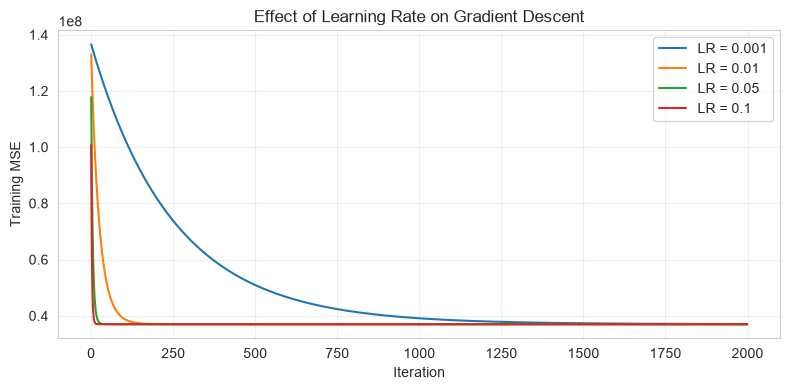

In [12]:
learning_rates = [0.001, 0.01, 0.05, 0.1]
rate_results = []
rate_histories = {}

for rate in learning_rates:
    _, history = batch_gradient_descent(
        X_train_gd, y_train_centered, learning_rate=rate, iterations=2000
    )
    rate_histories[rate] = history
    rate_results.append({"Learning Rate": rate, "Final Training MSE": history[-1]})

display(pd.DataFrame(rate_results).round(3))

plt.figure(figsize=(8, 4))
for rate, history in rate_histories.items():
    plt.plot(history, label=f"LR = {rate}")
plt.title("Effect of Learning Rate on Gradient Descent")
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# Too large a learning rate -> divergence
_, bad_history = batch_gradient_descent(X_train_gd, y_train_centered, learning_rate=1.1, iterations=30)
print("Training MSE with LR = 1.1 after 1, 10, 30 iterations:",
      [f"{bad_history[i]:.3e}" for i in (0, 9, 29)])

Training MSE with LR = 1.1 after 1, 10, 30 iterations: ['2.014e+08', '2.229e+14', '1.579e+29']


## 10. Effect of number of iterations

This shows how many iterations are needed before the Gradient Descent solution matches the closed-form solution.

In [14]:
iter_rows = []
for n in [10, 50, 100, 300, 1000, 5000]:
    w, hist = batch_gradient_descent(X_train_gd, y_train_centered, learning_rate=0.05, iterations=n)
    pred = X_test_gd @ w + y_mean
    iter_rows.append({"Iterations": n, "Final Training MSE": hist[-1],
                      "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                      "Test R2": r2_score(y_test, pred)})
display(pd.DataFrame(iter_rows).round(4))

,Iterations,Final Training MSE,Test RMSE,Test R2
0,10,4.965186e+07,7933.7964,0.6575
1,50,3.699125e+07,5983.9151,0.8051
2,100,3.698011e+07,5957.5869,0.8068
3,300,3.697986e+07,5956.3449,0.8069
4,1000,3.697986e+07,5956.3429,0.8069
5,5000,3.697986e+07,5956.3429,0.8069


## 11. Compare Gradient Descent with the closed-form solution

If Gradient Descent has converged, its weights should match scikit-learn's Linear Regression coefficients.

In [15]:
comparison_w = pd.DataFrame({
    "Feature": ["intercept"] + list(X.columns),
    "sklearn Linear Regression": np.r_[linear_model.intercept_ - y_mean, linear_model.coef_],
    "Batch Gradient Descent": gd_weights
})
display(comparison_w.round(4))
print("Max absolute difference:", float(np.max(np.abs(comparison_w.iloc[:, 1] - comparison_w.iloc[:, 2]))))

,Feature,sklearn Linear Regression,Batch Gradient Descent
0,intercept,-0.0000,0.0000
1,age,3472.9756,3472.9756
2,bmi,1927.8283,1927.8283
3,children,636.5012,636.5012
4,sex_male,-50.7497,-50.7497
5,smoker_yes,9234.3425,9234.3425
6,region_northwest,-168.9444,-168.9444
7,region_southeast,-371.7808,-371.7808
8,region_southwest,-284.6104,-284.6104


Max absolute difference: 7.048583938740194e-12


## 12. Actual versus predicted values and residuals

Points closer to the diagonal line indicate more accurate predictions. The residual plot checks whether the errors are randomly spread.

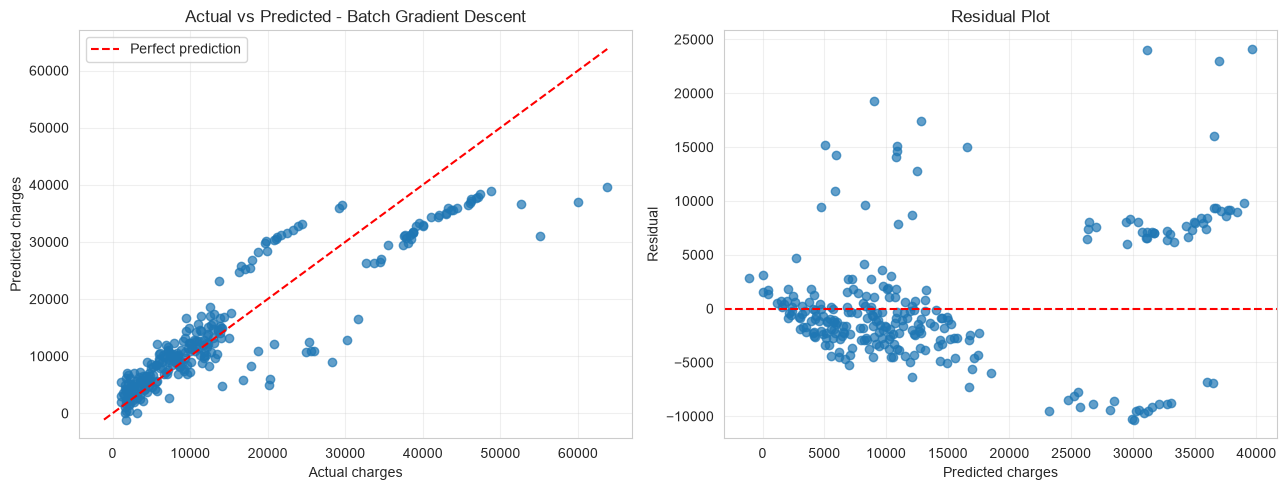

In [16]:
residuals = y_test - gd_predictions

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, gd_predictions, alpha=0.7)
limits = [min(y_test.min(), gd_predictions.min()), max(y_test.max(), gd_predictions.max())]
ax[0].plot(limits, limits, "r--", label="Perfect prediction")
ax[0].set_xlabel("Actual charges"); ax[0].set_ylabel("Predicted charges")
ax[0].set_title("Actual vs Predicted - Batch Gradient Descent"); ax[0].legend(); ax[0].grid(True, alpha=0.3)

ax[1].scatter(gd_predictions, residuals, alpha=0.7)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_xlabel("Predicted charges"); ax[1].set_ylabel("Residual")
ax[1].set_title("Residual Plot"); ax[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Final model comparison

Both models are evaluated on the same held-out test set. Lower MAE, MSE and RMSE are better; higher R² is better.

In [17]:
comparison = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(comparison.round(3))
if abs(comparison["RMSE"].max() - comparison["RMSE"].min()) < 0.01:
    print(f"Both models give the same test RMSE ({comparison['RMSE'].iloc[0]:.2f}) - Gradient Descent has fully converged.")
else:
    best_model = comparison.iloc[0]
    print(f"Lowest test RMSE: {best_model['Model']} ({best_model['RMSE']:.2f})")

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression (Batch GD),4177.046,3.547802e+07,5956.343,0.807
1,Linear Regression,4177.046,3.547802e+07,5956.343,0.807


Both models give the same test RMSE (5956.34) - Gradient Descent has fully converged.


## 14. Result and conclusion

This practical builds a Linear Regression model to predict medical insurance charges and implements Batch Gradient Descent for the same model from scratch with NumPy. MAE, MSE, RMSE and R² are used to evaluate performance on the test set.

- The Linear Regression model explains about **81%** of the variation in charges (R² ≈ 0.81) with an average error (MAE) of about **4,177 USD**.
- Batch Gradient Descent converges to the same weights as the closed-form solution, giving practically identical metrics, which confirms the implementation is correct.
- The **learning rate** controls convergence speed: 0.001 is slow, 0.05–0.1 converge quickly, and a value above about 1 makes the loss diverge.
- **Feature scaling** is important; it lets a single learning rate work well for all features.
- Smoking status, age and BMI are the most influential features.
- The residual plot shows larger errors for high-cost patients, because the true relationship is not perfectly linear (smoking and BMI interact). This is a limitation of linear models.

**Note:** This dataset is for education purposes. The model is not a real insurance pricing tool.

**Dataset reference:** Medical Cost Personal Datasets (insurance.csv) – https://github.com/stedy/Machine-Learning-with-R-datasets